# Lab 6, Task 2B: Experimental Receiver Diversity

Use the SIMO field in the dual-channel capture to compare SC, EGC, and MRC with measured channel coefficients.

In [2]:
from pathlib import Path
import sys
import numpy as np
from IPython.display import display, Image

def find_lab_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / "support" / "lab6_dsp.py").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook from the Lab 6 folder tree")

LAB_ROOT = find_lab_root()
sys.path.insert(0, str(LAB_ROOT / "support"))
import lab6_dsp as lab
import lab6_tools as tools
print("Lab folder:", LAB_ROOT.name)


Lab folder: Lab6


## Load one acquired frame

In [3]:
capture_dir = LAB_ROOT/'work/captures'
summary = __import__('json').loads((capture_dir/'lab6_measurement_summary.json').read_text())
tx_gains_db = tuple(int(value) for value in summary['experiment']['tx_gains_db'])
gain = tx_gains_db[1]
waveform = lab.build_waveform()
rx0 = lab.load_complex64(capture_dir/f'lab6_rx_tx{gain}_ch0_c64.dat', lab.CAPTURE_SAMPLES)
rx1 = lab.load_complex64(capture_dir/f'lab6_rx_tx{gain}_ch1_c64.dat', lab.CAPTURE_SAMPLES)
noise0 = lab.load_complex64(capture_dir/'lab6_noise_ch0_c64.dat')[:250000]
noise1 = lab.load_complex64(capture_dir/'lab6_noise_ch1_c64.dat')[:250000]
if noise0.size < 250000 or noise1.size < 250000:
    raise ValueError('Each noise record must contain at least 250000 samples.')
capture = lab.analyze_hardware_capture(rx0,rx1,noise0,noise1,waveform)
frame = capture['analyzed_frames'][0]
r = frame['payload_symbols_rx']
h = frame['simo_channel']
print('SIMO channel:',h)

SIMO channel: [0.30484301+0.9496475j  0.17128772+1.35659233j]


## Combine the two measured branches

`r` contains two rows of received QPSK symbols. `h` contains one complex flat-fading estimate per receive branch.

In [4]:
h_matrix = np.repeat(h[:,None],r.shape[1],axis=1)

best = np.argmax(np.abs(h)**2)
sc = (r[best] / h[best]) / lab.DIGITAL_PEAK
egc_weights = np.exp(-1j * np.angle(h))
egc = (
    np.sum(egc_weights[:, None] * r, axis=0)
    / np.sum(np.abs(h))
) / lab.DIGITAL_PEAK
mrc = (
    np.sum(np.conj(h)[:, None] * r, axis=0)
    / np.sum(np.abs(h)**2)
) / lab.DIGITAL_PEAK
outputs={'sc':sc,'egc':egc,'mrc':mrc}
for name,z in outputs.items():
    errors=np.count_nonzero(lab.qpsk_detect(z)!=waveform.payload_bits)
    print(name.upper(),'errors',errors,'BER',errors/waveform.payload_bits.size,'EVM',lab.rms_evm(z,waveform.payload_symbols))

SC errors 0 BER 0.0 EVM 0.09636212878027776
EGC errors 0 BER 0.0 EVM 0.09559051409074473
MRC errors 0 BER 0.0 EVM 0.09571617194848195


## Plotting supplied

<span style='color:#1464b4'><b>Report:</b> Include both branch constellations, all three combined constellations, BER or error counts, EVM, and a received-quality and received power
comparison across TX gain.</span>

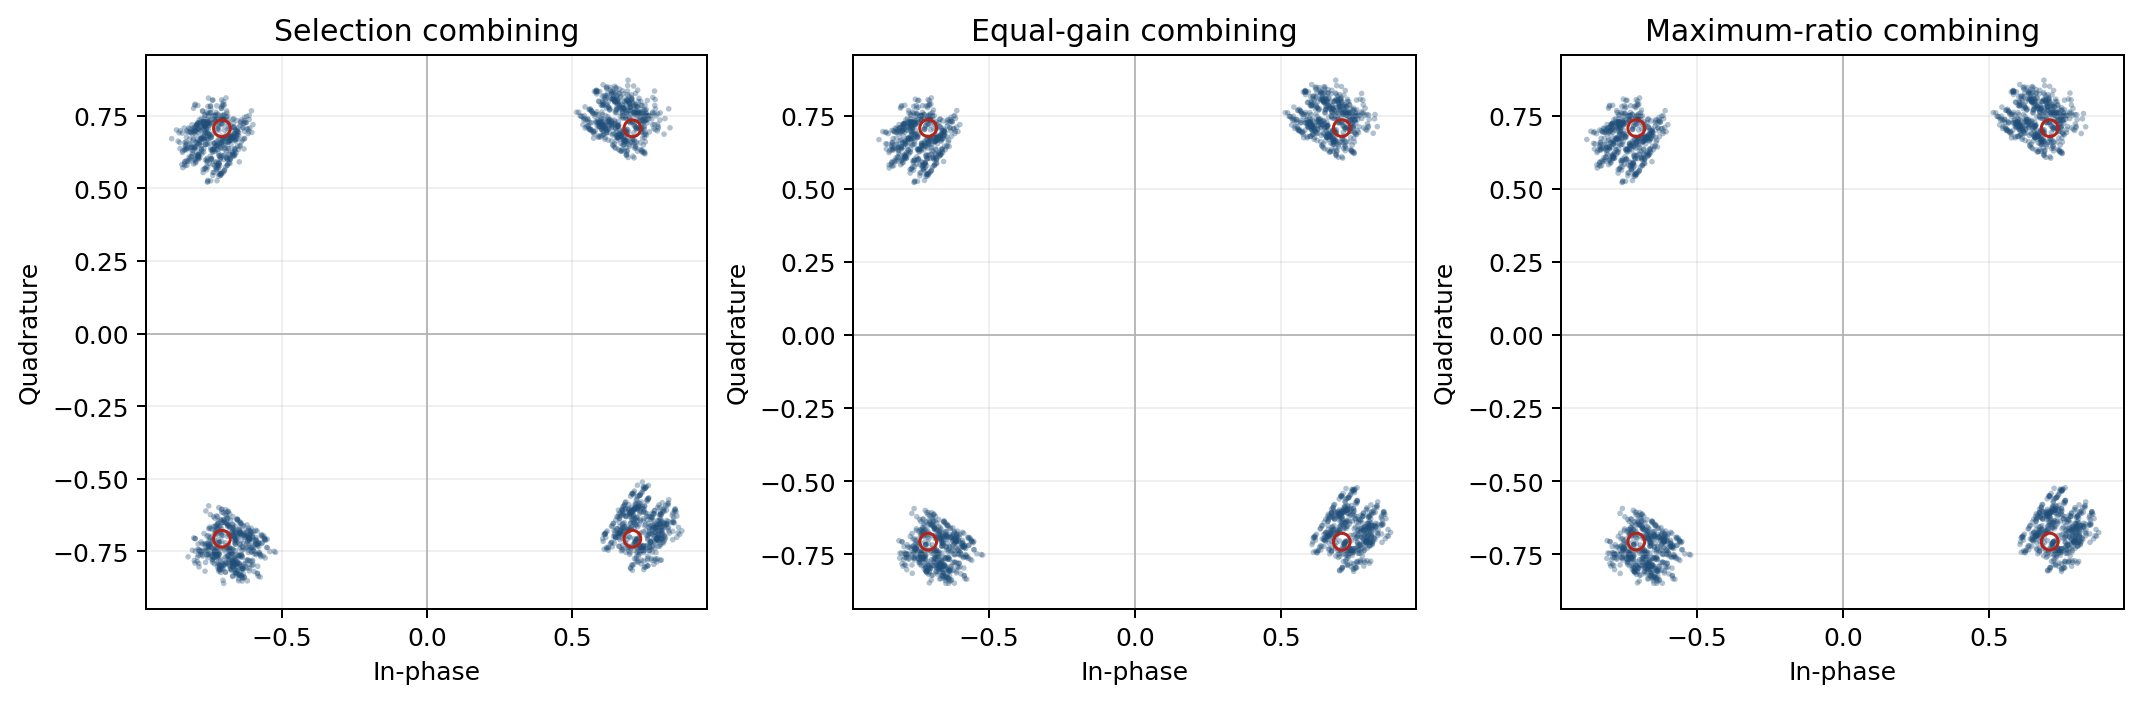

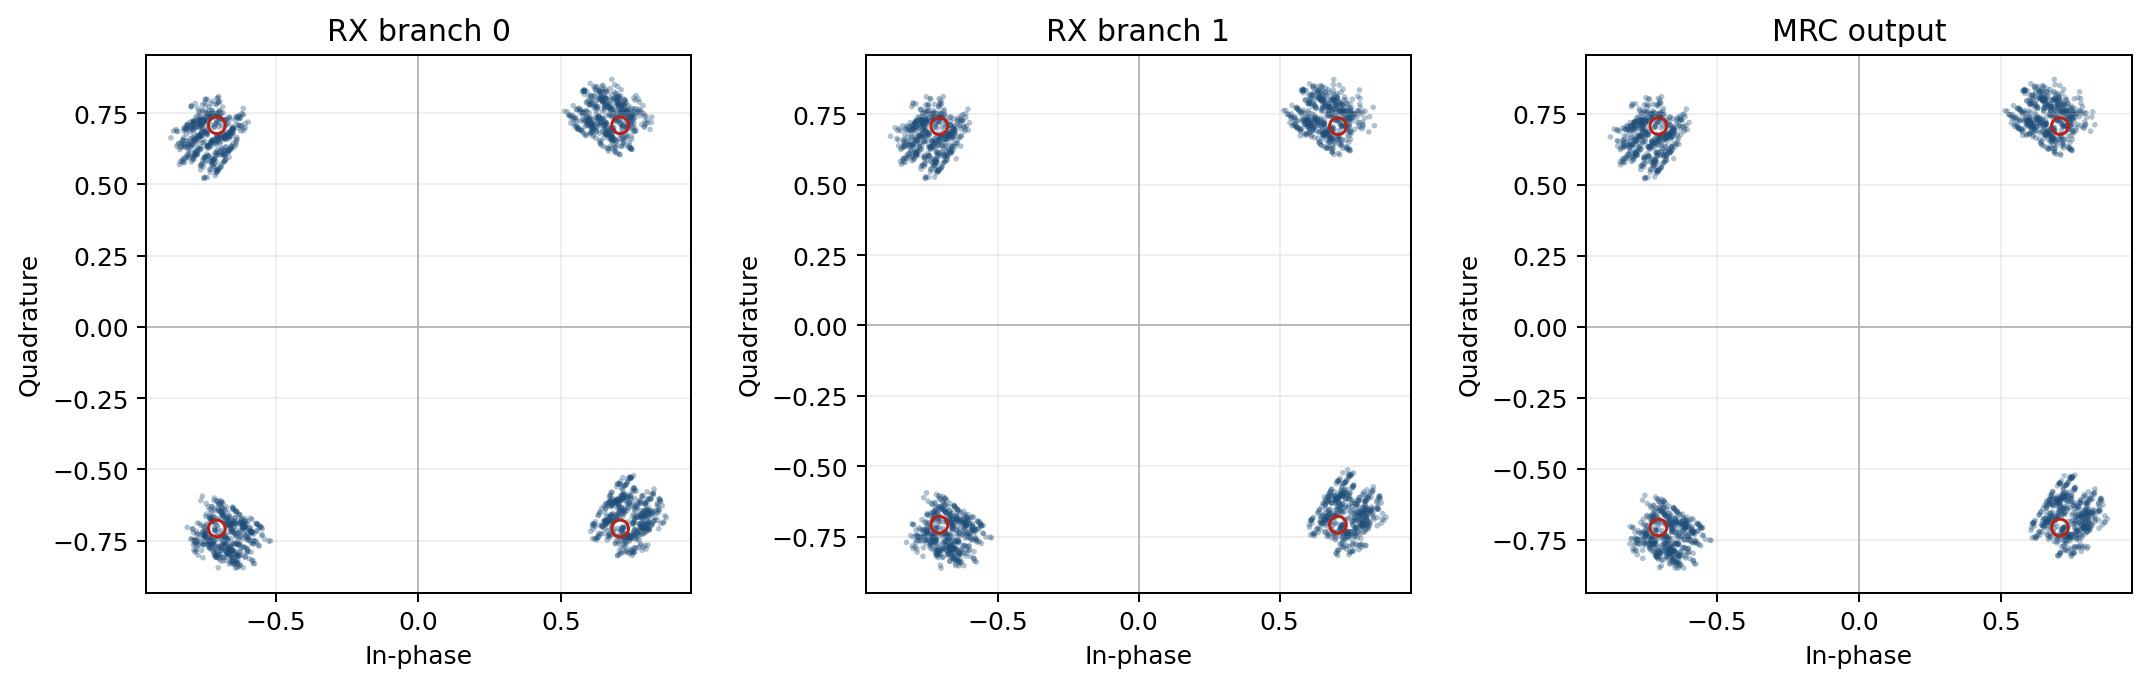

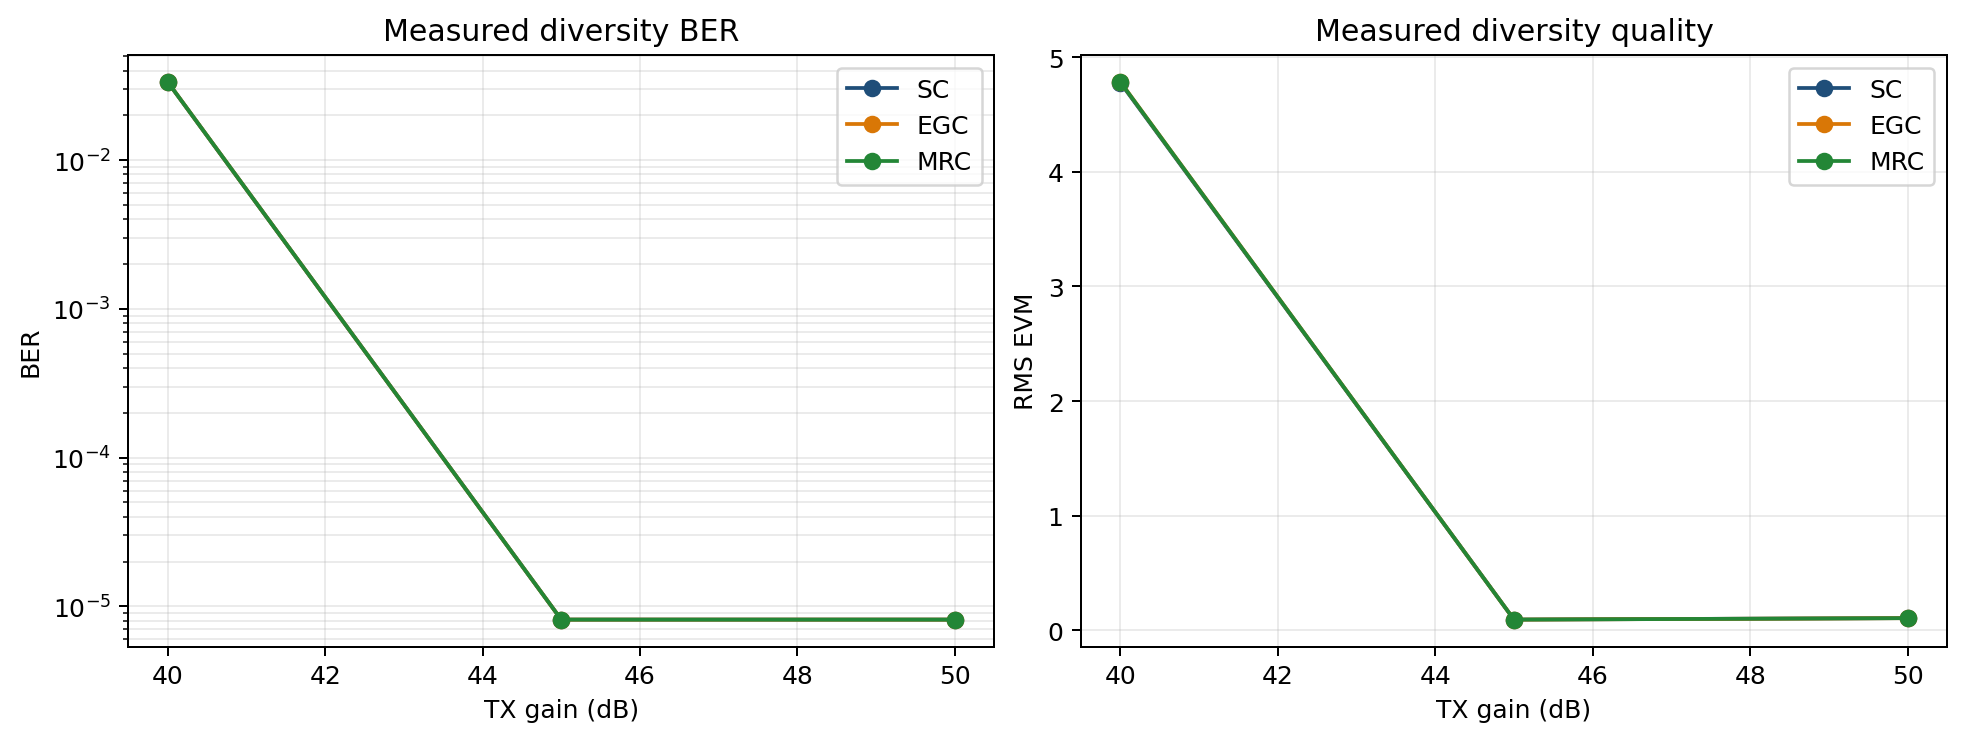

In [5]:
out = LAB_ROOT/'work/figures/task2_student_diversity_outputs.png'
tools.plot_diversity_outputs(outputs,out)
display(Image(filename=str(out),width=1000))
figure_dir = LAB_ROOT / 'work/figures'
hardware_results = tools.analyze_hardware(capture_dir, figure_dir)
display(Image(
    filename=str(figure_dir / 'task2_hardware_diversity_constellations.png'),
    width=1000
))
display(Image(
    filename=str(figure_dir / 'task2_hardware_diversity_metrics.png'),
    width=1000
))

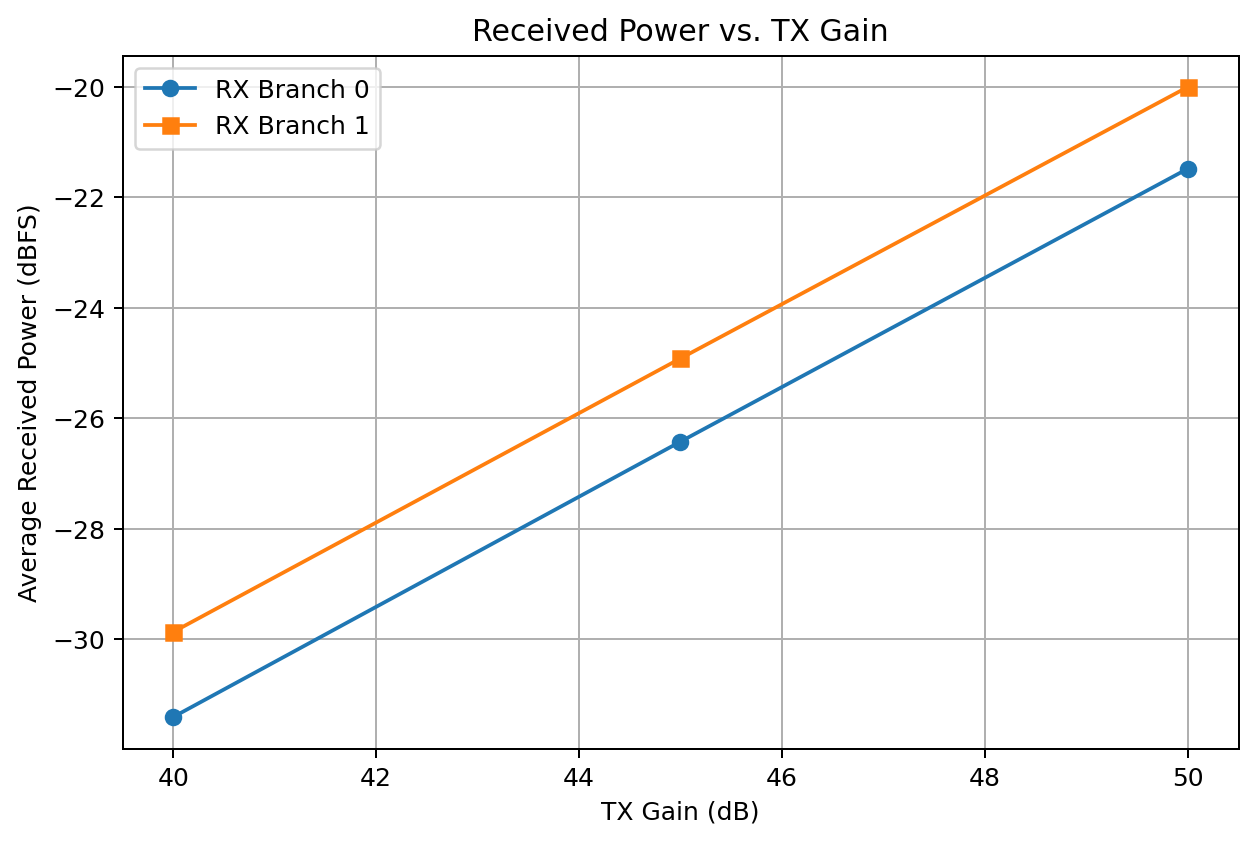

In [5]:
import matplotlib.pyplot as plt
rx0_power_db = []
rx1_power_db = []
for gain in tx_gains_db:
    rx0 = lab.load_complex64(
        capture_dir / f'lab6_rx_tx{gain}_ch0_c64.dat',
        lab.CAPTURE_SAMPLES
    )
    rx1 = lab.load_complex64(
        capture_dir / f'lab6_rx_tx{gain}_ch1_c64.dat',
        lab.CAPTURE_SAMPLES
    )
    p0 = np.mean(np.abs(rx0)**2)
    p1 = np.mean(np.abs(rx1)**2)
    rx0_power_db.append(10 * np.log10(p0))
    rx1_power_db.append(10 * np.log10(p1))
plt.figure(figsize=(8, 5))
plt.plot(tx_gains_db, rx0_power_db, 'o-', label='RX Branch 0')
plt.plot(tx_gains_db, rx1_power_db, 's-', label='RX Branch 1')
plt.xlabel('TX Gain (dB)')
plt.ylabel('Average Received Power (dBFS)')
plt.title('Received Power vs. TX Gain')
plt.grid(True)
plt.legend()
plt.savefig(
    LAB_ROOT / 'work/figures/task2_received_power_vs_tx_gain.png',
    dpi=180,
    bbox_inches='tight'
)
from IPython.display import display, Image
display(Image(
    filename=str(LAB_ROOT / 'work/figures/task2_received_power_vs_tx_gain.png'),
    width=900
))


<span style='color:#1464b4'><b>Report:</b> Compare measured trends with the Task 1B simulation.</span>

The measured diversity results followed the same overall trend as the Task 1B simulation in that performance improved as signal conditions became stronger. In the simulation, increasing SNR reduced BER, and MRC provided the best performance, followed by EGC and then SC. Similarly, in the experimental measurements, increasing TX gain from 40 dB to 45 dB significantly reduced BER and RMS EVM, with little additional improvement between 45 dB and 50 dB. However, unlike the simulation, the measured BER and EVM curves for SC, EGC, and MRC were nearly identical. This is likely because the two receive branches experienced very similar channel conditions, resulting in limited diversity gain. As a result, all three combining methods produced similar constellation quality and error performance. Overall, the measurements confirmed the expected improvement in signal quality with increasing TX gain, but the performance differences between SC, EGC, and MRC were much smaller than predicted by the idealized Rayleigh-fading simulation in Task 1B.

<span style='color:#1464b4'><b>Report:</b> Explain when diversity is preferable to
spatial multiplexing.</span>

Diversity is preferred when the goal is reliable communication rather than maximum throughput. By combining multiple received copies of the same signal, diversity reduces fading and improves BER and EVM. Spatial multiplexing increases data rate by transmitting multiple streams simultaneously but requires stronger channel conditions and good separation between spatial channels.